# ESMFold2 — Predicted disorder


## 1. Data source/acquisition

Query RCSB for single-chain, protein-only X-ray or cryo-EM structures released after September 2021 and through 20 July 2026, with resolution ≤3.5 Å and length 40–1000. Download sequences, metadata and experimental structures. Use the pre-October-2021 PDB sequence collection as the homology reference. Every public response and download has a checksum.

**Environment.** The verified run uses Linux, Python 3.11 and a CUDA GPU. The full-length inference stage waits for at least 40 GiB of free GPU memory. Create a Jupyter kernel with the tested public packages:

```bash
python3.11 -m venv .venv-esmfold2
source .venv-esmfold2/bin/activate
python -m pip install torch==2.6.0 --index-url https://download.pytorch.org/whl/cu124
python -m pip install transformers==5.22.2 huggingface-hub==1.31.0 safetensors==0.8.0 numpy==2.4.6 pandas==3.0.3 scipy==1.16.2 matplotlib==3.10.8 biopython==1.87 biotite==1.6.0 gemmi==0.7.5 ipykernel jupyterlab
python -m ipykernel install --user --name esmfold2-inline --display-name 'ESMFold2 inline'
```

Select **ESMFold2 inline** before Run All. All custom calculation code is below. MMseqs2 and the model checkpoints are acquired by the visible cells. The optional `ESMFOLD_OPUS_R1_ROOT` selects a cache/output directory; leave it unset for notebook-local storage. `ESMFOLD_CHECKPOINT` can select a verified converted checkpoint. The GPU-ready-file setting is optional scheduling coordination and is not required for a standalone run. Numerical settings include the [documented native bfloat16 model](https://huggingface.co/docs/transformers/v5.21.0/en/model_doc/esmfold2), float32 diffusion coordinates, `float32_matmul_precision='high'` and no outer autocast; these settings are bound to each prediction receipt.



In [1]:
from pathlib import Path
import urllib.error
from concurrent.futures import ThreadPoolExecutor
from collections import Counter,defaultdict
import os,json,hashlib,urllib.request,subprocess,tarfile,io,time,socket,math,re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display,Image
os.environ['OMP_NUM_THREADS']='2';os.environ['MKL_NUM_THREADS']='2';os.environ['OPENBLAS_NUM_THREADS']='2'
ROOT=Path(os.environ.get('ESMFOLD_OPUS_R1_ROOT',str(Path.cwd()/'calculations/opus-r1'))).resolve();ROOT.mkdir(parents=True,exist_ok=True)
RAW=ROOT/'source_data';RAW.mkdir(exist_ok=True)
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(url,path,expected=None):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True);receipt=path.with_suffix(path.suffix+'.source.json')
    if path.is_file() and receipt.is_file():
        known=json.loads(receipt.read_text())
        if sha256_file(path)!=known['sha256']:raise ValueError('Cached source bytes changed: '+str(path))
        if expected and known['sha256']!=expected:raise ValueError('Source fingerprint differs')
        return known
    temporary=path.with_suffix(path.suffix+'.partial')
    request=urllib.request.Request(url,headers={'User-Agent':'SPECTRA-protein-analysis/1.0'})
    for attempt in range(10):
        try:
            with urllib.request.urlopen(request,timeout=180) as response,temporary.open('wb') as stream:
                headers={key:response.headers.get(key) for key in ['ETag','Last-Modified','Content-Length']}
                while True:
                    block=response.read(1024*1024)
                    if not block:break
                    stream.write(block)
            break
        except urllib.error.HTTPError as error:
            if error.code not in [429,500,502,503,504] or attempt==9:raise
            value=error.headers.get('Retry-After','')
            try:requested_delay=float(value)
            except ValueError:
                from email.utils import parsedate_to_datetime
                try:requested_delay=max(0,parsedate_to_datetime(value).timestamp()-time.time())
                except (TypeError,ValueError):requested_delay=0
            delay=max(requested_delay,min(15*2**attempt,180))
            print(f'Public source HTTP {error.code}; retrying in {delay:.0f}s: {url}',flush=True);time.sleep(delay)
        except (urllib.error.URLError,TimeoutError,ConnectionError):
            if attempt==9:raise
            time.sleep(min(15*2**attempt,180))
    digest=sha256_file(temporary)
    if expected and digest!=expected:raise ValueError('Downloaded source fingerprint differs')
    temporary.replace(path)
    record={'url':url,'sha256':digest,'bytes':path.stat().st_size,'headers':headers}
    receipt.write_text(json.dumps(record,indent=2));return record

SELECTION_SEED=20260720
SOURCE_RELEASE_END='2026-07-20T23:59:59Z'
DISCOVERY_SIZE=700;CONFIRMATION_SIZE=1400


In [2]:
import gzip,random

def request_json(url,payload,name):
    path=RAW/(name+'.json');receipt=path.with_suffix('.receipt.json')
    query_sha=hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()
    if path.exists() and receipt.exists():
        record=json.loads(receipt.read_text())
        if record['query_sha256']!=query_sha or record['response_sha256']!=sha256_file(path):raise ValueError('Cached API response binding differs')
        return json.loads(path.read_text())
    request=urllib.request.Request(url,data=json.dumps(payload).encode(),headers={'Content-Type':'application/json','User-Agent':'SPECTRA-protein-analysis/1.0'})
    for attempt in range(4):
        try:
            with urllib.request.urlopen(request,timeout=180) as response:data=json.load(response)
            break
        except Exception:
            if attempt==3:raise
            time.sleep(2)
    path.write_text(json.dumps(data));receipt.write_text(json.dumps({'url':url,'query_sha256':query_sha,'response_sha256':sha256_file(path)},indent=2))
    return data

def term(attribute,operator,value):return {'type':'terminal','service':'text','parameters':{'attribute':attribute,'operator':operator,'value':value}}
nodes=[term('entity_poly.rcsb_entity_polymer_type','exact_match','Protein'),{'type':'group','logical_operator':'or','nodes':[term('exptl.method','exact_match','X-RAY DIFFRACTION'),term('exptl.method','exact_match','ELECTRON MICROSCOPY')]},term('rcsb_entry_info.resolution_combined','less_or_equal',3.5),term('rcsb_accession_info.initial_release_date','greater','2021-09-30T23:59:59Z'),term('rcsb_accession_info.initial_release_date','less_or_equal',SOURCE_RELEASE_END),term('entity_poly.rcsb_sample_sequence_length','range',{'from':40,'to':1000}),term('rcsb_entry_info.deposited_polymer_entity_instance_count','equals',1),term('rcsb_entry_info.selected_polymer_entity_types','exact_match','Protein (only)')]
entity_ids=[]
for start in range(0,100000,10000):
    query={'query':{'type':'group','logical_operator':'and','nodes':nodes},'return_type':'polymer_entity','request_options':{'paginate':{'start':start,'rows':10000},'results_content_type':['experimental']}}
    response=request_json('https://search.rcsb.org/rcsbsearch/v2/query',query,f'candidate_ids_{start:05}')
    entity_ids.extend(row['identifier'] for row in response.get('result_set',[]))
    if start+10000>=response['total_count']:break
if len(entity_ids)!=response['total_count']:raise ValueError('Incomplete candidate query')
entity_ids=sorted(set(entity_ids))
GQL="""query($ids:[String!]!){polymer_entities(entity_ids:$ids){rcsb_id entity_poly{pdbx_seq_one_letter_code_can rcsb_sample_sequence_length rcsb_entity_polymer_type} rcsb_polymer_entity_container_identifiers{entry_id asym_ids auth_asym_ids uniprot_ids} entry{rcsb_accession_info{initial_release_date} rcsb_entry_info{resolution_combined} exptl{method}}}}"""
def get_batch(start):
    data=request_json('https://data.rcsb.org/graphql',{'query':GQL,'variables':{'ids':entity_ids[start:start+150]}},f'candidate_metadata_{start:05}')
    if data.get('errors'):raise ValueError(data['errors'])
    return data['data']['polymer_entities']
metadata=[]
with ThreadPoolExecutor(max_workers=6) as pool:
    for batch in pool.map(get_batch,range(0,len(entity_ids),150)):
        for entity in batch:
            if entity is None:raise ValueError('An acquired candidate lacks entity metadata')
            poly=entity.get('entity_poly') or {};ident=entity.get('rcsb_polymer_entity_container_identifiers') or {};entry=entity.get('entry') or {};info=entry.get('rcsb_entry_info') or {};dates=entry.get('rcsb_accession_info') or {}
            metadata.append({'entity_id':entity['rcsb_id'],'entry_id':ident['entry_id'],'auth_asym_ids':ident.get('auth_asym_ids') or [],'asym_ids':ident.get('asym_ids') or [],'uniprot_ids':ident.get('uniprot_ids') or [],'sequence':poly.get('pdbx_seq_one_letter_code_can') or '', 'resolution':(info.get('resolution_combined') or [np.nan])[0],'release_date':dates.get('initial_release_date'),'method':'; '.join(x['method'] for x in entry.get('exptl') or [])})
metadata=pd.DataFrame(metadata)
reference_entries=[]
for start in range(0,500000,10000):
    query={'query':{'type':'group','logical_operator':'and','nodes':[term('rcsb_accession_info.initial_release_date','less_or_equal','2021-09-30T23:59:59Z'),term('rcsb_entry_info.polymer_entity_count_protein','greater',0)]},'return_type':'entry','request_options':{'paginate':{'start':start,'rows':10000},'results_content_type':['experimental']}}
    response=request_json('https://search.rcsb.org/rcsbsearch/v2/query',query,f'reference_entries_{start:06}')
    reference_entries.extend(row['identifier'].upper() for row in response.get('result_set',[]))
    if start+10000>=response['total_count']:break
if len(reference_entries)!=response['total_count']:raise ValueError('Incomplete reference query')
acquire('https://files.wwpdb.org/pub/pdb/derived_data/pdb_seqres.txt.gz',RAW/'pdb_seqres.txt.gz')
TOOLS=ROOT/'third_party';TOOLS.mkdir(exist_ok=True);MMSEQS=TOOLS/'mmseqs/bin/mmseqs'
if not MMSEQS.exists():
    archive=TOOLS/'mmseqs18.tar.gz';acquire('https://github.com/soedinglab/MMseqs2/releases/download/18-8cc5c/mmseqs-linux-avx2.tar.gz',archive)
    with tarfile.open(archive,'r:gz') as bundle:bundle.extractall(TOOLS,filter='data')
print('Public candidate entities:',len(metadata),'reference entries:',len(reference_entries),'MMseqs:',subprocess.check_output([str(MMSEQS),'version'],text=True).strip())


Public candidate entities: 15645 reference entries: 178555 MMseqs: 8cc5ce367b5638c4306c2d7cfc652dd099a4643f


## 2. Data processing

Exclude sequences with >5% nonstandard residues; preserve positions by replacing remaining nonstandard symbols with X. Cluster at 30% identity and 80% coverage, shuffle sorted representatives with seed 20260720, and select 700 discovery and 1400 confirmation chains before coordinate quality control. Exclude chains with fewer than 30 resolved Cα positions; report the resulting sample counts.


In [3]:
STD=set('ACDEFGHIKLMNPQRSTVWY')
metadata['sequence']=metadata.sequence.str.upper().str.replace(r'\s+','',regex=True)
metadata['len']=metadata.sequence.str.len()
metadata['nonstandard_fraction']=metadata.sequence.map(lambda seq:sum(aa not in STD for aa in seq)/max(1,len(seq)))
eligible=metadata[metadata['len'].between(40,1000)&metadata.nonstandard_fraction.le(.05)&metadata.auth_asym_ids.map(bool)].copy()
# Replace nonstandard residues with X, retaining all residue positions.
eligible['sequence']=eligible.sequence.map(lambda seq:''.join(aa if aa in STD else 'X' for aa in seq))
eligible=eligible.sort_values('entity_id').reset_index(drop=True)
all_fasta=ROOT/'eligible_candidates.fasta';all_fasta.write_text(''.join('>'+r.entity_id+'\n'+r.sequence+'\n' for r in eligible.itertuples()))
cluster_path=ROOT/'cluster30_cluster.tsv';binding={'candidate_sha256':sha256_file(all_fasta),'binary_sha256':sha256_file(MMSEQS),'identity':.3,'coverage':.8,'seed':SELECTION_SEED}
cluster_receipt=ROOT/'cluster30.receipt.json'
if not cluster_path.exists() or not cluster_receipt.exists() or json.loads(cluster_receipt.read_text()).get('binding')!=binding:
    subprocess.run([str(MMSEQS),'easy-cluster',str(all_fasta),str(ROOT/'cluster30'),str(ROOT/'cluster_tmp'),'--min-seq-id','0.30','-c','0.8','--threads','2','-v','1'],check=True)
    cluster_receipt.write_text(json.dumps({'binding':binding,'sha256':sha256_file(cluster_path)}))
if sha256_file(cluster_path)!=json.loads(cluster_receipt.read_text())['sha256']:raise ValueError('Cluster table checksum mismatch')
clusters=pd.read_csv(cluster_path,sep='\t',header=None,names=['representative','entity_id'])
representatives=sorted(clusters.representative.unique());random.Random(SELECTION_SEED).shuffle(representatives)
if len(representatives)<DISCOVERY_SIZE+CONFIRMATION_SIZE:raise ValueError('Insufficient independent clusters for the specified panels')
selected=representatives[:DISCOVERY_SIZE+CONFIRMATION_SIZE]
split_by_id={entity:'discovery' if i<DISCOVERY_SIZE else 'confirmation' for i,entity in enumerate(selected)}
features=eligible[eligible.entity_id.isin(selected)].copy();features['split']=features.entity_id.map(split_by_id)
features['cluster_size']=features.entity_id.map(clusters.groupby('representative').size())
features=features.sort_values(['split','entity_id']).reset_index(drop=True)
features['sequence_sha256']=features.sequence.map(lambda value:hashlib.sha256(value.encode()).hexdigest())
def get_native(entry):return entry,acquire('https://files.rcsb.org/download/'+entry+'.cif.gz',RAW/(entry+'.cif.gz'))
with ThreadPoolExecutor(max_workers=6) as pool:structure_sources=dict(pool.map(get_native,sorted(features.entry_id.unique())))
from Bio.PDB.MMCIF2Dict import MMCIF2Dict
from Bio.SeqUtils import seq1
def read_cif_fields(path):
    if str(path).endswith('.gz'):
        with gzip.open(path,'rt') as stream:return MMCIF2Dict(stream)
    return MMCIF2Dict(str(path))
def load_ref_ca(path,auth_chain=None,label_chain=None):
    fields=read_cif_fields(path);names=fields['_atom_site.label_atom_id'];out={};aa={};first_chain=None
    for i,name in enumerate(names):
        if name!='CA':continue
        if fields.get('_atom_site.pdbx_PDB_model_num',['1']*len(names))[i]!='1':continue
        if fields.get('_atom_site.label_alt_id',['.']*len(names))[i] not in ['.','?','A']:continue
        chain=fields['_atom_site.auth_asym_id'][i];label=fields['_atom_site.label_asym_id'][i]
        if first_chain is None:first_chain=chain
        if auth_chain is not None and chain!=auth_chain:continue
        if auth_chain is None and label_chain is not None and label!=label_chain:continue
        if auth_chain is None and label_chain is None and chain!=first_chain:continue
        index=fields['_atom_site.label_seq_id'][i]
        if index in ['.','?']:continue
        index=int(index)
        if index<1 or index in out:continue
        out[index]=np.array([float(fields['_atom_site.Cartn_'+axis][i]) for axis in ['x','y','z']])
        aa[index]=seq1(fields['_atom_site.label_comp_id'][i],custom_map={'MSE':'M'},undef_code='X')
    return out,aa
native={};coverage=[]
for row in features.itertuples():
    coords,aas=load_ref_ca(RAW/(row.entry_id+'.cif.gz'),auth_chain=row.auth_asym_ids[0])
    coords={i:v for i,v in coords.items() if 1<=i<=row.len}
    native[row.entity_id]=coords;coverage.append({'entity_id':row.entity_id,'native_ca':len(coords),'native_coverage':len(coords)/row.len})
features=features.merge(pd.DataFrame(coverage),on='entity_id',validate='one_to_one')
excluded=features[features.native_ca.lt(30)].copy();features=features[features.native_ca.ge(30)].copy()
print('Selected panel sizes and coordinate exclusions:');display(features.groupby('split').size());display(excluded[['entity_id','split','native_ca']])
QUERY=ROOT/'panel_queries.fasta';QUERY.write_text(''.join('>'+r.entity_id+'\n'+r.sequence+'\n' for r in features.itertuples()))
REFERENCE=ROOT/'precutoff_sequences.fasta';precutoff=set(reference_entries);reference_count=0
with gzip.open(RAW/'pdb_seqres.txt.gz','rt') as stream,REFERENCE.open('w') as destination:
    header=None;parts=[]
    def emit_reference(header,parts):
        if header is None:return 0
        tokens=header.split();identifier=tokens[0];sequence=''.join(parts).upper()
        if 'mol:protein' not in tokens or identifier.split('_')[0].upper() not in precutoff or len(sequence)<40:return 0
        destination.write('>'+identifier+'\n'+''.join(aa if aa in STD else 'X' for aa in sequence)+'\n');return 1
    for line in stream:
        if line.startswith('>'):reference_count+=emit_reference(header,parts);header=line[1:].strip();parts=[]
        else:parts.append(line.strip())
    reference_count+=emit_reference(header,parts)
print('Reference protein chains:',reference_count)


Selected panel sizes and coordinate exclusions:


split
confirmation    1399
discovery        700
dtype: int64

,entity_id,split,native_ca
1010,9C4N_1,confirmation,9


Reference protein chains: 584345


## 3. Axis definition and level construction

Calculate sequence length, FoldIndex disorder (21-residue window), Wootton–Federhen complexity (12-residue window), composition, and coverage-weighted identity of the highest-bit-score pre-cutoff match. Construct the displayed fixed bins and within-split disorder quintiles from input features.


In [4]:
KD = {'A': 1.8, 'R': -4.5, 'N': -3.5, 'D': -3.5, 'C': 2.5, 'Q': -3.5, 'E': -3.5, 'G': -0.4, 'H': -3.2, 'I': 4.5, 'L': 3.8, 'K': -3.9, 'M': 1.9, 'F': 2.8, 'P': -1.6, 'S': -0.8, 'T': -0.7, 'W': -0.9, 'Y': -1.3, 'V': 4.2}

POS = set('RK')

NEG = set('DE')

HYDRO = set('AILMFVWC')

STD = set('ACDEFGHIKLMNPQRSTVWY')

def foldindex_disorder(seq, w=21):
    """Per-residue FoldIndex over sliding window; return fraction disordered (FI<0)."""
    seq = [c for c in seq if c in KD]
    n = len(seq)
    if n < w:
        H = np.mean([(KD[c] + 4.5) / 9.0 for c in seq]) if seq else 0.5
        ch = abs(sum((1 for c in seq if c in POS)) - sum((1 for c in seq if c in NEG))) / max(1, n)
        fi = 2.785 * H - abs(ch) - 1.151
        return float(fi < 0)
    h = np.array([(KD[c] + 4.5) / 9.0 for c in seq])
    q = np.array([1.0 if c in POS else -1.0 if c in NEG else 0.0 for c in seq])
    half = w // 2
    dis = np.zeros(n, dtype=bool)
    csum_h = np.concatenate([[0], np.cumsum(h)])
    csum_q = np.concatenate([[0], np.cumsum(q)])
    for i in range(n):
        a = max(0, i - half)
        b = min(n, i + half + 1)
        L = b - a
        Hm = (csum_h[b] - csum_h[a]) / L
        chg = abs((csum_q[b] - csum_q[a]) / L)
        fi = 2.785 * Hm - chg - 1.151
        dis[i] = fi < 0
    return float(dis.mean())

def wf_complexity(seq, w=12):
    """Wootton-Federhen local complexity K in [0,1]; return fraction of windows
    with K<0.5 (low complexity) and mean K."""
    seq = [c for c in seq if c in STD]
    n = len(seq)
    if n < w:
        from collections import Counter
        c = Counter(seq)
        L = len(seq) or 1
        K = -sum((v / L * math.log(v / L, 20) for v in c.values())) if L > 1 else 0
        return (float(K < 0.5), K)
    logfac = lambda m: math.lgamma(m + 1)
    lowc = 0
    Ks = []
    from collections import Counter
    for i in range(0, n - w + 1):
        win = seq[i:i + w]
        c = Counter(win)
        lnOmega = logfac(w) - sum((logfac(v) for v in c.values()))
        K = lnOmega / math.log(20) / w
        Ks.append(K)
        if K < 0.5:
            lowc += 1
    return (lowc / len(Ks), float(np.mean(Ks)))

def comp_entropy(seq):
    from collections import Counter
    seq = [c for c in seq if c in STD]
    L = len(seq) or 1
    c = Counter(seq)
    return -sum((v / L * math.log(v / L, 20) for v in c.values()))

def sequence_features(seq):
    seq = seq.upper()
    s = [c for c in seq if c in STD]
    L = len(s)
    lowc_frac, meanK = wf_complexity(s)
    return {'length': len(seq), 'disorder_frac': round(foldindex_disorder(s), 4), 'lowcomplex_frac': round(lowc_frac, 4), 'mean_wf_complexity': round(meanK, 4), 'comp_entropy': round(comp_entropy(s), 4), 'frac_charged': round(sum((1 for c in s if c in POS | NEG)) / max(1, L), 4), 'frac_hydrophobic': round(sum((1 for c in s if c in HYDRO)) / max(1, L), 4)}
computed=pd.DataFrame([{'entity_id':r.entity_id,**sequence_features(r.sequence)} for r in features.itertuples()])
features=features.merge(computed,on='entity_id',validate='one_to_one')
search=ROOT/'homology_hits.tsv';receipt=ROOT/'homology_search.receipt.json'
search_binding={'query_sha256':sha256_file(QUERY),'reference_sha256':sha256_file(REFERENCE),'binary_sha256':sha256_file(MMSEQS),'sensitivity':7.5,'max_seqs':50,'evalue':10}
if not search.exists() or not receipt.exists() or json.loads(receipt.read_text()).get('binding')!=search_binding:
    subprocess.run([str(MMSEQS),'easy-search',str(QUERY),str(REFERENCE),str(search),str(ROOT/'homology_tmp'),'-s','7.5','--max-seqs','50','-e','10','-a','--format-output','query,target,fident,alnlen,qcov,tcov,qstart,qend,tstart,tend,bits,evalue,qaln,taln','--threads','2','-v','1'],check=True)
    receipt.write_text(json.dumps({'binding':search_binding,'sha256':sha256_file(search)}))
if sha256_file(search)!=json.loads(receipt.read_text())['sha256']:raise ValueError('Homology-search checksum mismatch')
hits=pd.read_csv(search,sep='\t',header=None,names=['query','target','fident','alnlen','qcov','tcov','qstart','qend','tstart','tend','bits','evalue','qaln','taln'])
best=hits.sort_values(['query','bits','target'],ascending=[True,False,True],kind='stable').drop_duplicates('query')
best_hits={r['query']:r for r in best.to_dict('records')}
features['homology']=features.entity_id.map(lambda entity:float(best_hits[entity]['fident']*best_hits[entity]['qcov']) if entity in best_hits else 0.)
features['homology_level']=pd.cut(features.homology,[-1e-9,.1,.3,.5,.7,.9,1.000001],right=False,labels=['0–<0.1','0.1–<0.3','0.3–<0.5','0.5–<0.7','0.7–<0.9','0.9–1'])
features['length_level']=pd.cut(features['len'],[39,127,199,287,399,599,1000],labels=['40–127','128–199','200–287','288–399','400–599','600–1000'])
features['disorder_fixed_level']=pd.cut(features.disorder_frac,[-1e-9,.25,.35,.45,.55,1.00001],right=False,labels=['0–<0.25','0.25–<0.35','0.35–<0.45','0.45–<0.55','0.55–1'])
features['disorder_level']=features.groupby('split').disorder_frac.transform(lambda s:pd.qcut(s,5,labels=False,duplicates='drop')+1).map(lambda x:f'Q{int(x)}')
features['release_year']=features.release_date.str[:4].astype(int)
features['is_em']=features.method.str.contains('ELECTRON MICROSCOPY').astype(int)
features.to_csv(ROOT/'axis_features.csv',index=False)
display(features[['entity_id','split','len','homology','homology_level','disorder_frac','disorder_level','native_coverage']])

AXIS_SETTINGS=('disorder_frac','disorder_level')


,entity_id,split,len,homology,homology_level,disorder_frac,disorder_level,native_coverage
0,10DT_1,confirmation,177,0.734564,0.7–<0.9,0.5311,Q5,1.000000
1,10PA_1,confirmation,321,0.797755,0.7–<0.9,0.4393,Q4,0.987539
2,10WZ_1,confirmation,132,0.189216,0.1–<0.3,0.4697,Q4,0.666667
3,10XO_1,confirmation,93,0.171570,0.1–<0.3,0.1505,Q1,0.903226
4,10XW_1,confirmation,241,0.000000,0–<0.1,0.1701,Q1,0.995851
...,...,...,...,...,...,...,...,...
2094,9YAH_1,discovery,157,0.245520,0.1–<0.3,0.2930,Q2,0.770701
2095,9YFB_1,discovery,285,0.606001,0.5–<0.7,0.2281,Q2,0.954386
2096,9YFW_1,discovery,656,0.000000,0–<0.1,0.1570,Q1,0.859756
2097,9Z71_1,discovery,184,0.000000,0–<0.1,0.1630,Q1,0.989130


## 4. Model results or released scores

Use Transformers 5.22.2 ESMFold2 with the verified checkpoint, seed 0, three loops and 50 diffusion sampling steps. No fine-tuning is performed. Prediction caches are checked against the exact sequence, settings, checkpoint and output checksum. Download AlphaFold DB v6 structures and pre-cutoff template structures; align their residues and score them against the same experimental coordinates. Calculate Cα lDDT, fixed-correspondence TM-score after Kabsch fitting, and GDT-TS explicitly below. Record unavailable reference predictions and show coverage; never replace a failed reference download with a model score.


In [5]:
# Hugging Face Transformers converter, Apache-2.0, commit3d87599b23ff5f630de770e08eeed64950e25a9e.
import argparse
import glob
import json
import os
import torch
from huggingface_hub import HfApi, save_torch_state_dict, snapshot_download
from safetensors.torch import load_file
from transformers import EsmcConfig, EsmcTokenizer
esmc__LEGACY_FIELDS = ('vocab_size', 'initializer_range', 'pad_token_id', 'tie_word_embeddings', 'mask_token_id', 'classifier_dropout')
esmc__LEGACY_RENAMES = {'hidden_size': 'd_model', 'num_attention_heads': 'n_heads', 'num_hidden_layers': 'n_layers'}
esmc__LEGACY_DROP_KEYS = {'architectures', 'model_type', 'transformers_version'}
esmc__WEIGHT_KEY_RENAMES = (('embed.', 'embed_tokens.'), ('transformer.blocks.', 'layers.'), ('transformer.norm.', 'norm.'), ('attn.layernorm_qkv.layer_norm_weight', 'input_layernorm.weight'), ('attn.layernorm_qkv.layer_norm_bias', 'input_layernorm.bias'), ('attn.q_ln.', 'self_attn.q_norm.'), ('attn.k_ln.', 'self_attn.k_norm.'), ('attn.out_proj.', 'self_attn.o_proj.'), ('ffn.layer_norm_weight', 'post_attention_layernorm.weight'), ('ffn.layer_norm_bias', 'post_attention_layernorm.bias'), ('ffn.fc2_weight', 'mlp.down_proj.weight'), ('lm_head.0.', 'lm_head.dense.'), ('lm_head.2.', 'lm_head.layer_norm.'), ('lm_head.3.', 'lm_head.decoder.'))
esmc__PACKED_QKV_SUFFIX = 'attn.layernorm_qkv.weight'
esmc__PACKED_GATE_UP_SUFFIX = 'ffn.fc1_weight'
esmc__WEIGHT_KEY_DROP_SUFFIX = '_extra_state'

def esmc__read_json(directory: str) -> dict:
    with open(os.path.join(directory, 'config.json')) as f:
        return json.load(f)

def esmc_build_esmc_config_dict(esmc_dir: str) -> dict:
    old = esmc__read_json(esmc_dir)
    config = {field: old[field] for field in esmc__LEGACY_FIELDS if field in old}
    for port_field, legacy_field in esmc__LEGACY_RENAMES.items():
        config[port_field] = old[legacy_field]
    config['intermediate_size'] = int((8 / 3 * config['hidden_size'] + 255) // 256 * 256)
    if 'dtype' in old:
        config['dtype'] = old['dtype']
    mapped = {*esmc__LEGACY_FIELDS, *esmc__LEGACY_RENAMES.values(), 'dtype'}
    unexpected = set(old) - (mapped | esmc__LEGACY_DROP_KEYS)
    if unexpected:
        raise ValueError(f'unmapped fields in the source ESMC config: {sorted(unexpected)}')
    return config

def esmc_build_config(esmc_dir: str) -> EsmcConfig:
    config = esmc_build_esmc_config_dict(esmc_dir)
    config['architectures'] = ['EsmcForMaskedLM']
    return EsmcConfig.from_dict(config)

def esmc_convert_esmc_state_dict(state_dict: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    converted: dict[str, torch.Tensor] = {}
    for key, tensor in state_dict.items():
        if key.endswith(esmc__WEIGHT_KEY_DROP_SUFFIX):
            continue
        for old, new in esmc__WEIGHT_KEY_RENAMES:
            key = key.replace(old, new)
        if key.endswith(esmc__PACKED_QKV_SUFFIX):
            base = key[:-len(esmc__PACKED_QKV_SUFFIX)]
            q, k, v = (chunk.clone() for chunk in torch.chunk(tensor, 3, dim=0))
            converted.update({base + 'self_attn.q_proj.weight': q, base + 'self_attn.k_proj.weight': k, base + 'self_attn.v_proj.weight': v})
        elif key.endswith(esmc__PACKED_GATE_UP_SUFFIX):
            base = key[:-len(esmc__PACKED_GATE_UP_SUFFIX)]
            gate, up = (chunk.clone() for chunk in torch.chunk(tensor, 2, dim=0))
            converted.update({base + 'mlp.gate_proj.weight': gate, base + 'mlp.up_proj.weight': up})
        else:
            converted[key] = tensor
    return converted

def esmc__load_state_dict(directory: str) -> dict[str, torch.Tensor]:
    shards = sorted(glob.glob(os.path.join(directory, '*.safetensors')))
    if not shards:
        raise FileNotFoundError(f'no *.safetensors weights found in {directory}')
    state_dict: dict[str, torch.Tensor] = {}
    for shard in shards:
        state_dict.update(load_file(shard))
    return state_dict

def esmc_save_tokenizer(output_dir: str) -> None:
    EsmcTokenizer().save_pretrained(output_dir)


In [6]:
# Hugging Face Transformers converter, Apache-2.0, commit3d87599b23ff5f630de770e08eeed64950e25a9e.
import argparse
import glob
import json
import os
import re
import torch
from huggingface_hub import HfApi, save_torch_state_dict, snapshot_download
from safetensors.torch import load_file
from transformers import EsmcTokenizer, EsmFold2Config, EsmFold2Model
fold__LEGACY_FIELDS = ('num_loops', 'structure_head.diffusion_module.sigma_data', 'structure_head.diffusion_module.fourier_dim', 'structure_head.gamma_0', 'structure_head.gamma_min', 'structure_head.noise_scale', 'structure_head.step_scale', 'structure_head.inference_num_steps', 'confidence_head.num_plddt_bins', 'confidence_head.num_pde_bins', 'confidence_head.num_pae_bins', 'confidence_head.min_dist', 'confidence_head.max_dist', 'confidence_head.distogram_bins', 'lm_encoder.lm_dropout', 'lm_encoder.per_loop_lm_dropout')
fold__LEGACY_RENAMES = {'hidden_size': 'd_single', 'pairwise_hidden_size': 'd_pair', 'single_inputs_size': 'inputs.d_inputs', 'sliding_window': 'inputs.atom_encoder.swa_window_size', 'folding_trunk_num_hidden_layers': 'folding_trunk.n_layers', 'parcae_num_coda_layers': 'parcae.coda_n_layers', 'num_relative_residx_bins': 'n_relative_residx_bins', 'num_relative_chain_bins': 'n_relative_chain_bins', 'atom_encoder.hidden_size': 'inputs.atom_encoder.d_atom', 'atom_encoder.num_hidden_layers': 'inputs.atom_encoder.n_blocks', 'atom_encoder.num_attention_heads': 'inputs.atom_encoder.n_heads', 'atom_encoder.spatial_rope_base_frequency': 'inputs.atom_encoder.spatial_rope_base_frequency', 'atom_encoder.num_spatial_rope_pairs_per_axis': 'inputs.atom_encoder.n_spatial_rope_pairs_per_axis', 'atom_encoder.num_uid_rope_pairs': 'inputs.atom_encoder.n_uid_rope_pairs', 'atom_encoder.uid_rope_base_frequency': 'inputs.atom_encoder.uid_rope_base_frequency', 'structure_head.diffusion_module.atom_encoder.hidden_size': 'structure_head.diffusion_module.c_atom', 'structure_head.diffusion_module.atom_encoder.num_hidden_layers': 'structure_head.diffusion_module.atom_num_blocks', 'structure_head.diffusion_module.atom_encoder.num_attention_heads': 'structure_head.diffusion_module.atom_num_heads', 'structure_head.diffusion_module.hidden_size': 'structure_head.diffusion_module.c_token', 'structure_head.diffusion_module.num_hidden_layers': 'structure_head.diffusion_module.token_num_blocks', 'structure_head.diffusion_module.num_attention_heads': 'structure_head.diffusion_module.token_num_heads', 'structure_head.num_distogram_bins': 'structure_head.distogram_bins', 'structure_head.num_diffusion_samples': 'num_diffusion_samples', 'structure_head.inference_sigma_max_ratio': 'structure_head.inference_s_max', 'structure_head.inference_sigma_min_ratio': 'structure_head.inference_s_min', 'structure_head.inference_exponent': 'structure_head.inference_p', 'confidence_head.num_hidden_layers': 'confidence_head.folding_trunk.n_layers', 'msa_encoder.hidden_size': 'msa_encoder.d_msa', 'msa_encoder.outer_hidden_size': 'msa_encoder.d_hidden', 'msa_encoder.num_hidden_layers': 'msa_encoder.n_layers', 'msa_encoder.num_attention_heads': 'msa_encoder.n_heads_msa', 'msa_encoder.head_dim': 'msa_encoder.msa_head_width', 'lm_encoder.num_hidden_layers': 'lm_encoder.n_layers'}
fold__LEGACY_PORT_PATHS = (*fold__LEGACY_FIELDS, *fold__LEGACY_RENAMES)
fold__LEGACY_WIDTH_INPUTS = {'inputs.atom_encoder.expansion_ratio', 'structure_head.diffusion_module.transition_multiplier'}
fold__LEGACY_TRANSITION_EXPANSION_RATIO = 4
fold__LEGACY_DROP_PATHS = {'architectures', 'model_type', 'transformers_version', 'type', 'esmc_id', 'inputs.atom_encoder.d_token', 'lm_d_model', 'lm_num_layers', 'lm_dropout', 'disable_msa_features', 'force_lm_dropout_during_inference', 'folding_trunk.n_heads', 'folding_trunk.dropout', 'structure_head.train_noise_log_mean', 'structure_head.train_noise_log_std', 'structure_head.diffusion_module.c_z', 'structure_head.diffusion_module.c_s_inputs', 'structure_head.diffusion_module.relpos_r_max', 'structure_head.diffusion_module.relpos_s_max', 'msa_encoder.enabled', 'msa_encoder_overwrite', 'lm_encoder.enabled', 'confidence_head.enabled', 'confidence_head.folding_trunk.n_heads', 'confidence_head.folding_trunk.dropout', 'parcae.enabled', 'parcae.max_steps', 'parcae.min_steps', 'parcae.poisson_mean'}
fold__WEIGHT_KEY_RENAMES = (('inputs_embedder.atom_attention_encoder.', 'input_embedder.atom_encoder.'), ('structure_head.diffusion_module.', 'structure_head.'), ('structure_head.atom_encoder.coords_linear.', 'structure_head.coords_linear.'), ('.atom_transformer.', '.'), ('._engine.', '.'), ('.blocks.', '.layers.'), ('.attn.', '.self_attn.'), ('.w_up.', '.gate_up_proj.'), ('.w_down.', '.down_proj.'), ('.lin_swish.', '.mlp.gate_up_proj.'), ('.lin_out.', '.mlp.down_proj.'), ('.ffn.w12.', '.mlp.gate_up_proj.'), ('.ffn.w3.', '.mlp.down_proj.'), ('.ffn.', '.mlp.'), ('fourier.w', 'fourier.frequencies'), ('fourier.b', 'fourier.phases'), ('parcae_', 'parcae.'), ('parcae.log_a', 'parcae.log_state_decay'), ('parcae.b_cont', 'parcae.input_matrix_continuous'), ('parcae.readout.', 'parcae.out_proj.'), ('parcae.coda.', 'parcae.output_stack.'), ('output_mlp.0.', 'output_fc1.'), ('output_mlp.2.', 'output_fc2.'), ('adaln_modulation.1.', 'adaln_linear.'), ('adaln.s_gate.', 'adaln.gate_proj.'), ('adaln.s_shift.', 'adaln.shift_proj.'), ('adaln.s_scale', 'adaln.cond_norm.weight'), ('base_z_linear.0.', 'pair_input_norm.'), ('base_z_linear.1.', 'pair_proj.'), ('base_z_mlp.0.', 'single_to_pair.'), ('base_z_mlp.1.', 'pair_output_norm.'), ('base_z_combine', 'layer_weights'), ('compute_bias.0.', 'bias_norm.'), ('compute_bias.1.', 'bias_proj.'), ('.z_input_norm.', '.pair_input_norm.'), ('.z_proj.', '.pair_proj.'), ('.z_transitions.0.', '.pair_transition_0.'), ('.z_transitions.1.', '.pair_transition_1.'), ('.s_input_norm.', '.single_input_norm.'), ('.s_proj.', '.single_proj.'), ('.s_transitions.0.', '.single_transition_0.'), ('.s_transitions.1.', '.single_transition_1.'), ('.s_to_token.', '.single_to_token.'), ('.s_step_norm.', '.single_step_norm.'), ('.g_proj.', '.gate_proj.'), ('z_init_1.', 'input_embedder.pair_init_1.'), ('z_init_2.', 'input_embedder.pair_init_2.'), ('rel_pos.', 'input_embedder.rel_pos.'), ('token_bonds.', 'input_embedder.token_bonds.'), ('outer_product_mean.W.', 'outer_product_mean.input_proj.'), ('outer_product_mean.Wout.', 'outer_product_mean.output_proj.'), ('msa_pair_weighted_averaging.Wv.', 'msa_pair_weighted_averaging.v_proj.'), ('msa_pair_weighted_averaging.Wgate.', 'msa_pair_weighted_averaging.gate_proj.'), ('msa_pair_weighted_averaging.Wout.', 'msa_pair_weighted_averaging.o_proj.'), ('confidence_head.plddt_ln.', 'confidence_head.plddt_layernorm.'), ('confidence_head.pae_ln.', 'confidence_head.pae_layernorm.'), ('confidence_head.pde_ln.', 'confidence_head.pde_layernorm.'), ('confidence_head.resolved_ln.', 'confidence_head.resolved_layernorm.'), ('confidence_head.s_inputs_norm.', 'confidence_head.input_embedder.single_inputs_norm.'), ('confidence_head.z_norm.', 'confidence_head.input_embedder.pair_norm.'), ('confidence_head.s_to_z.', 'confidence_head.input_embedder.single_to_pair.'), ('confidence_head.s_to_z_transpose.', 'confidence_head.input_embedder.single_to_pair_transpose.'), ('confidence_head.s_to_z_prod_in1.', 'confidence_head.input_embedder.single_to_pair_prod_in1.'), ('confidence_head.s_to_z_prod_in2.', 'confidence_head.input_embedder.single_to_pair_prod_in2.'), ('confidence_head.s_to_z_prod_out.', 'confidence_head.input_embedder.single_to_pair_prod_out.'))
fold__PACKED_QKV_SUFFIX = 'self_attn.Wqkv.weight'
fold__WEIGHT_KEY_DROPS = ('confidence_head.s_norm.', 'confidence_head.s_inputs_to_single.', 'confidence_head.s_input_to_s.')

def fold__read_json(directory: str) -> dict:
    with open(os.path.join(directory, 'config.json')) as f:
        return json.load(f)

def fold__get_path(cfg: dict, path: str):
    node = cfg
    for part in path.split('.'):
        node = node[part]
    return node

def fold__leaf_paths(cfg: dict, prefix: str='') -> set[str]:
    paths: set[str] = set()
    for key, value in cfg.items():
        dotted = f'{prefix}{key}'
        paths |= fold__leaf_paths(value, f'{dotted}.') if isinstance(value, dict) else {dotted}
    return paths

def fold__swiglu_width(hidden_size: int, expansion_ratio: int) -> int:
    return (expansion_ratio * (hidden_size // 3) * 2 + 255) // 256 * 256

def fold__derive_widths(old: dict, config: dict) -> None:
    defaults = EsmFold2Config()
    inputs_atom = config['atom_encoder']
    diffusion = config['structure_head']['diffusion_module']
    denoiser_atom = diffusion['atom_encoder']
    inputs_atom['intermediate_size'] = fold__swiglu_width(inputs_atom['hidden_size'], fold__get_path(old, 'inputs.atom_encoder.expansion_ratio'))
    inputs_atom['output_dim'] = config['single_inputs_size'] - (2 * defaults.num_res_types + 1)
    denoiser_atom['intermediate_size'] = fold__swiglu_width(denoiser_atom['hidden_size'], 2)
    denoiser_atom['output_dim'] = diffusion['hidden_size']
    for rope_field in ('spatial_rope_base_frequency', 'num_spatial_rope_pairs_per_axis', 'num_uid_rope_pairs', 'uid_rope_base_frequency'):
        denoiser_atom[rope_field] = inputs_atom[rope_field]
    transition_multiplier = fold__get_path(old, 'structure_head.diffusion_module.transition_multiplier')
    diffusion['intermediate_size'] = transition_multiplier * diffusion['hidden_size']
    diffusion['pair_intermediate_size'] = transition_multiplier * config['pairwise_hidden_size']
    config['msa_encoder']['intermediate_size'] = fold__LEGACY_TRANSITION_EXPANSION_RATIO * config['msa_encoder']['hidden_size']
    config['pair_transition_intermediate_size'] = fold__LEGACY_TRANSITION_EXPANSION_RATIO * config['pairwise_hidden_size']

def fold_build_legacy_config(old: dict) -> dict:
    config: dict = {}
    for port_path in fold__LEGACY_PORT_PATHS:
        node = config
        parts = port_path.split('.')
        for part in parts[:-1]:
            node = node.setdefault(part, {})
        node[parts[-1]] = fold__get_path(old, fold__LEGACY_RENAMES.get(port_path, port_path))
    if 'dtype' in old:
        config['dtype'] = old['dtype']
    fold__derive_widths(old, config)
    if not old.get('msa_encoder_overwrite', True):
        raise ValueError('msa_encoder_overwrite=false is not supported: the port removed the additive MSA path')
    mapped = {fold__LEGACY_RENAMES.get(port_path, port_path) for port_path in fold__LEGACY_PORT_PATHS}
    unexpected = fold__leaf_paths(old) - (mapped | fold__LEGACY_DROP_PATHS | fold__LEGACY_WIDTH_INPUTS | {'dtype'})
    if unexpected:
        raise ValueError(f'unmapped fields in the source ESMFold2 config: {sorted(unexpected)}')
    return config

def fold__load_state_dict(directory: str) -> dict[str, torch.Tensor]:
    shards = sorted(glob.glob(os.path.join(directory, '*.safetensors')))
    if not shards:
        raise FileNotFoundError(f'no *.safetensors weights found in {directory}')
    state_dict: dict[str, torch.Tensor] = {}
    for shard in shards:
        state_dict.update(load_file(shard))
    return state_dict

def fold_build_config(esmfold2_dir: str, esmc_dir: str) -> EsmFold2Config:
    config = fold_build_legacy_config(fold__read_json(esmfold2_dir))
    config['architectures'] = ['EsmFold2Model']
    config['esmc_config'] = esmc_build_esmc_config_dict(esmc_dir)
    return EsmFold2Config.from_dict(config)

def fold_rename_trunk_keys(trunk: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    renamed: dict[str, torch.Tensor] = {}
    for key, tensor in trunk.items():
        if any((drop in key for drop in fold__WEIGHT_KEY_DROPS)):
            continue
        for old, new in fold__WEIGHT_KEY_RENAMES:
            key = key.replace(old, new)
        if key.endswith(fold__PACKED_QKV_SUFFIX):
            base = key[:-len('Wqkv.weight')]
            q, k, v = (chunk.clone() for chunk in torch.chunk(tensor, 3, dim=0))
            renamed.update({base + 'q_proj.weight': q, base + 'k_proj.weight': k, base + 'v_proj.weight': v})
        else:
            renamed[key] = tensor
    return fold__standardize_attention_keys(fold__fuse_transition_swiglu(fold__nest_diffusion_layers(renamed)))

def fold__nest_diffusion_layers(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    substitutions = (('\\.attn_blocks\\.(\\d+)\\.adaln\\.', '.layers.\\1.input_layernorm.'), ('\\.attn_blocks\\.(\\d+)\\.out_gate\\.', '.layers.\\1.attn_gate.'), ('\\.attn_blocks\\.(\\d+)\\.(pair_norm|pair_bias_proj)\\.', '.layers.\\1.\\2.'), ('\\.attn_blocks\\.(\\d+)\\.', '.layers.\\1.self_attn.'), ('\\.transition_blocks\\.(\\d+)\\.adaln\\.', '.layers.\\1.post_attention_layernorm.'), ('\\.transition_blocks\\.(\\d+)\\.output_gate\\.', '.layers.\\1.mlp_gate.'), ('\\.transition_blocks\\.(\\d+)\\.', '.layers.\\1.'))
    out: dict[str, torch.Tensor] = {}
    for key, tensor in renamed.items():
        for pattern, replacement in substitutions:
            key, count = re.subn(pattern, replacement, key)
            if count:
                break
        out[key] = tensor
    return out

def fold__standardize_attention_keys(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    out: dict[str, torch.Tensor] = {}
    for key, tensor in renamed.items():
        if 'token_transformer.layers.' in key and key.endswith('.kv_proj.weight'):
            base = key[:-len('kv_proj.weight')]
            k, v = (chunk.clone() for chunk in torch.chunk(tensor, 2, dim=0))
            out[base + 'k_proj.weight'] = k
            out[base + 'v_proj.weight'] = v
            continue
        if key.endswith('.self_attn.out_proj.weight') or ('token_transformer.layers.' in key and key.endswith('.out_proj.weight')):
            key = key.replace('.out_proj.weight', '.o_proj.weight')
        out[key] = tensor
    return out

def fold__fuse_transition_swiglu(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    for key in list(renamed):
        is_transition = '.pair_transition_' in key or '.single_transition_' in key
        if is_transition and key.endswith('.a_proj.weight'):
            base = key[:-len('a_proj.weight')]
            gate = renamed.pop(base + 'a_proj.weight')
            up = renamed.pop(base + 'b_proj.weight')
            renamed[base + 'mlp.gate_up_proj.weight'] = torch.cat([gate, up], dim=0)
        elif is_transition and key.endswith('.out_proj.weight'):
            renamed[key.replace('.out_proj.weight', '.mlp.down_proj.weight')] = renamed.pop(key)
    return renamed

def fold_merge_state_dict(esmfold2_dir: str, esmc_dir: str) -> dict[str, torch.Tensor]:
    trunk = fold__load_state_dict(esmfold2_dir)
    if any((k.startswith('esmc.') for k in trunk)):
        raise RuntimeError('the ESMFold2 checkpoint already contains esmc.* keys — already bundled?')
    trunk = fold_rename_trunk_keys(trunk)
    esmc = fold__load_state_dict(esmc_dir)
    kept = {k: v for k, v in esmc.items() if k.startswith('esmc.')}
    if not kept:
        raise RuntimeError(f'no esmc.* tensors found in {esmc_dir}')
    return {**trunk, **esmc_convert_esmc_state_dict(kept)}

def fold_check_against_model(state_dict: dict[str, torch.Tensor], config: EsmFold2Config) -> None:
    with torch.device('meta'):
        expected = {k: tuple(v.shape) for k, v in EsmFold2Model(config).state_dict().items()}
    missing = sorted(set(expected) - set(state_dict))
    unexpected = sorted(set(state_dict) - set(expected))
    mismatched = sorted((k for k in set(state_dict) & set(expected) if tuple(state_dict[k].shape) != expected[k]))
    if missing or unexpected or mismatched:
        raise ValueError(f'converted state dict does not match EsmFold2Model:\n  missing ({len(missing)}): {missing[:10]}\n  unexpected ({len(unexpected)}): {unexpected[:10]}\n  shape mismatch ({len(mismatched)}): ' + str([(k, tuple(state_dict[k].shape), expected[k]) for k in mismatched[:10]]))

def fold_save_tokenizer(output_dir: str) -> None:
    EsmcTokenizer().save_pretrained(output_dir)


In [7]:
from huggingface_hub import snapshot_download,save_torch_state_dict
import torch,transformers
from transformers import EsmFold2Model
from transformers.models.esmfold2.protein_utils import prepare_protein_features,output_to_pdb
torch.set_num_threads(2);torch.set_num_interop_threads(1)
if transformers.__version__!='5.22.2':raise RuntimeError('Use Transformers5.22.2 for this notebook')
CHECKPOINT=Path(os.environ.get('ESMFOLD_CHECKPOINT',str(ROOT/'model')))
if not (CHECKPOINT/'model.safetensors.index.json').is_file():
    fold_source=snapshot_download('biohub/ESMFold2',revision='1ebf0e3481a5184eb6171d40615c79e384b48796',allow_patterns=['config.json','*.safetensors','*.safetensors.index.json'])
    backbone_source=snapshot_download('biohub/ESMC-6B',revision='45b0fa5d7fb06faefbd5e3b89bdcef35d564e79a',allow_patterns=['config.json','*.safetensors','*.safetensors.index.json'])
    config=fold_build_config(fold_source,backbone_source)
    converted=fold_merge_state_dict(fold_source,backbone_source)
    fold_check_against_model(converted,config)
    CHECKPOINT.mkdir(parents=True,exist_ok=True);config.save_pretrained(str(CHECKPOINT));save_torch_state_dict(converted,str(CHECKPOINT))
    del converted
index_path=CHECKPOINT/'model.safetensors.index.json'
weight_index=json.loads(index_path.read_text())
if len(weight_index['weight_map'])!=2658:raise ValueError('Unexpected converted model tensor key count')
checkpoint_signature={'config_sha256':sha256_file(CHECKPOINT/'config.json'),'index_sha256':sha256_file(index_path)}
print('Model source: biohub/ESMFold2 revision1ebf0e3 +ESMC-6B revision45b0fa5;2658 converted parameter entries.')


Model source: biohub/ESMFold2 revision1ebf0e3 +ESMC-6B revision45b0fa5;2658 converted parameter entries.


In [8]:
PREDICTIONS=ROOT/'predictions';PREDICTIONS.mkdir(exist_ok=True)
torch.set_float32_matmul_precision('high')
settings={'float32_matmul_precision':'high','seed':0,'num_loops':3,'num_sampling_steps':50,'num_diffusion_samples':1,'transformers':transformers.__version__,'torch':torch.__version__,'precision':'native bfloat16 model, float32 diffusion coordinates, no outer autocast'}
def prediction_binding(row):return {'sequence_sha256':row.sequence_sha256,'settings':settings,'checkpoint':checkpoint_signature}
def cached_prediction(row):
    path=PREDICTIONS/(row.entity_id+'.pdb');receipt=path.with_suffix('.json')
    if not path.exists() or not receipt.exists():return False
    metadata=json.loads(receipt.read_text())
    return metadata['binding']==prediction_binding(row) and metadata['pdb_sha256']==sha256_file(path)
import fcntl
from contextlib import contextmanager
@contextmanager
def prediction_claim(row):
    handle=(PREDICTIONS/(row.entity_id+'.lock')).open('a')
    claimed=False
    try:
        try:fcntl.flock(handle,fcntl.LOCK_EX|fcntl.LOCK_NB);claimed=True
        except BlockingIOError:pass
        yield claimed and not cached_prediction(row)
    finally:
        if claimed:fcntl.flock(handle,fcntl.LOCK_UN)
        handle.close()
worker_limit=int(os.environ.get('ESMFOLD_WORKER_MAX_LENGTH','999999'))
pending=[row for row in features.itertuples() if row.len<=worker_limit and not cached_prediction(row)]
inferred_target_count=0
if pending:
    if not torch.cuda.is_available():raise RuntimeError('An available CUDA GPU is required for model prediction')
    if worker_limit<999999 and torch.cuda.mem_get_info()[0]<24*1024**3:raise RuntimeError('Shared GPU has fewer than24GB free before model loading')
    wait_deadline=time.time()+86400
    ready_file=os.environ.get('ESMFOLD_GPU_READY_FILE')
    while (ready_file and not Path(ready_file).is_file()) or torch.cuda.mem_get_info()[0]<40*1024**3:
        if time.time()>wait_deadline:raise TimeoutError('The assigned GPU did not have 40 GiB available for the full-length panel')
        print('Waiting for the assigned GPU to finish its existing work.',flush=True);time.sleep(60)
    model,loading=EsmFold2Model.from_pretrained(str(CHECKPOINT),dtype=torch.bfloat16,local_files_only=True,output_loading_info=True)
    failures={key:value for key,value in loading.items() if value and key in ['missing_keys','unexpected_keys','mismatched_keys','error_msgs','conversion_errors','skipped_pp_keys']}
    if failures:raise RuntimeError('Incomplete checkpoint loading: '+str(failures))
    model.esmc.to(torch.bfloat16);model=model.eval().cuda()
    for number,row in enumerate(pending,1):
        with prediction_claim(row) as claimed:
            if not claimed:continue
            torch.manual_seed(0);torch.cuda.manual_seed_all(0);started=time.time()
            inputs=prepare_protein_features(row.sequence,device=model.device)
            with torch.inference_mode():output=model.fold(**inputs,num_loops=3,num_sampling_steps=50,num_diffusion_samples=1)
            pdb=output_to_pdb(output,inputs,sample_idx=0);path=PREDICTIONS/(row.entity_id+'.pdb');path.write_text(pdb)
            record={'binding':prediction_binding(row),'pdb_sha256':sha256_file(path),'elapsed_seconds':time.time()-started,'gpu':torch.cuda.get_device_name(0)}
            path.with_suffix('.json').write_text(json.dumps(record,indent=2));inferred_target_count+=1;print(f'Prediction {number}/{len(pending)}: {row.entity_id}',flush=True)
            del output,inputs
    del model;torch.cuda.empty_cache()
if os.environ.get('ESMFOLD_INFERENCE_WORKER','0')!='1':
    deadline=time.time()+600
    while any(not cached_prediction(row) for row in features.itertuples()):
        if time.time()>deadline:raise TimeoutError('Incomplete prediction cache after waiting for active workers')
        for row in features.itertuples():
            if not cached_prediction(row):
                with prediction_claim(row) as unowned:
                    if unowned:raise RuntimeError('Missing prediction with no active worker: '+row.entity_id)
        time.sleep(10)


In [9]:
def load_pred_ca(path):
    return {int(line[22:26]):np.array([float(line[30:38]),float(line[38:46]),float(line[46:54])]) for line in Path(path).read_text().splitlines() if line.startswith('ATOM') and line[12:16].strip()=='CA' and line[16:17] in [' ','A']}
def _match(ref_ca, pred_ca):
    keys = sorted(set(ref_ca) & set(pred_ca))
    R = np.array([ref_ca[k] for k in keys])
    P = np.array([pred_ca[k] for k in keys])
    return (keys, R, P)

def lddt_ca(ref_ca, pred_ca, R0=15.0, thresholds=(0.5, 1.0, 2.0, 4.0)):
    """Global + per-residue lDDT on Cα over residues present in BOTH.
    Reference inclusion sphere R0 among resolved residues."""
    keys, R, P = _match(ref_ca, pred_ca)
    n = len(keys)
    if n < 4:
        return (None, None, n)
    dR = np.linalg.norm(R[:, None, :] - R[None, :, :], axis=-1)
    dP = np.linalg.norm(P[:, None, :] - P[None, :, :], axis=-1)
    mask = (dR < R0) & ~np.eye(n, dtype=bool)
    diff = np.abs(dR - dP)
    preserved = np.zeros_like(dR)
    for t in thresholds:
        preserved += diff < t
    preserved /= len(thresholds)
    per = np.full(n, np.nan)
    denom = mask.sum(axis=1)
    num = (preserved * mask).sum(axis=1)
    per[denom > 0] = num[denom > 0] / denom[denom > 0]
    glob = float(num.sum() / mask.sum()) if mask.sum() > 0 else None
    return (glob, dict(zip(keys, per.tolist())), n)

def kabsch(P, Q):
    Pc = P - P.mean(0)
    Qc = Q - Q.mean(0)
    H = Pc.T @ Qc
    U, S, Vt = np.linalg.svd(H)
    d = np.sign(np.linalg.det(Vt.T @ U.T))
    D = np.diag([1, 1, d])
    Rmat = Vt.T @ D @ U.T
    Pr = (Rmat @ Pc.T).T
    return (Pr, Qc)

def rmsd_tm_gdt(ref_ca, pred_ca):
    keys, R, P = _match(ref_ca, pred_ca)
    L = len(keys)
    if L < 4:
        return {'n': L}
    Pr, Rc = kabsch(P, R)
    di = np.linalg.norm(Pr - Rc, axis=1)
    rmsd = float(np.sqrt((di ** 2).mean()))
    d0 = 1.24 * (max(L, 15) - 15) ** (1 / 3) - 1.8
    d0 = max(d0, 0.5)
    tm = float(1.0 / L * np.sum(1.0 / (1.0 + (di / d0) ** 2)))
    gdt = float(np.mean([(di < t).mean() for t in (1, 2, 4, 8)]))
    return {'n': L, 'rmsd_ca': round(rmsd, 3), 'tmscore_ca': round(tm, 4), 'gdt_ts': round(gdt, 4)}

def score_all(ref_ca, pred_ca):
    g, per, n = lddt_ca(ref_ca, pred_ca)
    d = rmsd_tm_gdt(ref_ca, pred_ca)
    d['lddt_ca'] = round(g, 4) if g is not None else None
    d['n_scored'] = n
    return (d, per)
def build_template_pred(besthit, tmpl_ca):
    """Map best-hit alignment -> predicted target coords {target_label_seq_id: coord}."""
    qaln = besthit['qaln']
    taln = besthit['taln']
    qpos = besthit['qstart']
    tpos = besthit['tstart']
    pred = {}
    for qc, tc in zip(qaln, taln):
        if qc != '-' and tc != '-':
            if tpos in tmpl_ca:
                pred[qpos] = tmpl_ca[tpos]
        if qc != '-':
            qpos += 1
        if tc != '-':
            tpos += 1
    return pred
from Bio import Align
aligner=Align.PairwiseAligner(mode="local",match_score=2,mismatch_score=-1,open_gap_score=-10,extend_gap_score=-.5)
def build_af_pred(entity_seq, af_coords, af_seq, af_pos):
    """Align entity seq to AFDB seq; map entity residue index(1-based) -> AFDB coord."""
    if not af_seq:
        return {}
    try:
        aln = aligner.align(entity_seq, af_seq)[0]
    except Exception:
        return {}
    pred = {}
    for (qs, qe), (ts, te) in zip(aln.aligned[0], aln.aligned[1]):
        for k in range(qe - qs):
            q = qs + k
            t = ts + k
            afresid = af_pos[t]
            if afresid in af_coords:
                pred[q + 1] = af_coords[afresid]
    return pred
REFERENCE_RESULTS=[]
for number,row in enumerate(features.itertuples(),1):
    result={'entity_id':row.entity_id,'template_status':'no_hit','afdb_status':'no_uniprot'};ref=native[row.entity_id];hit=best_hits.get(row.entity_id)
    template_prediction={}
    if hit is not None:
        entry,chain=hit['target'].split('_',1);path=RAW/(entry.upper()+'.cif.gz');acquire('https://files.rcsb.org/download/'+entry.upper()+'.cif.gz',path)
        template_coords,_=load_ref_ca(path,auth_chain=chain)
        template_prediction=build_template_pred(hit,template_coords)
        result['template_status']='ok' if len(set(ref)&set(template_prediction))>=4 else 'insufficient_overlap'
    if result['template_status']=='ok':
        metrics,_=score_all(ref,template_prediction);result.update({'template_'+key:value for key,value in metrics.items()})
    elif result['template_status']=='no_hit':
        result.update(template_tmscore_ca=0.,template_lddt_ca=0.,template_gdt_ts=0.,template_n_scored=0)
    af_prediction={}
    for accession in row.uniprot_ids:
        af_path=RAW/f'AF-{accession}-F1-model_v6.cif'
        try:acquire(f'https://alphafold.ebi.ac.uk/files/AF-{accession}-F1-model_v6.cif',af_path)
        except urllib.error.HTTPError as error:
            if error.code==404:result['afdb_status']='not_available_v6';continue
            raise
        af_coords,aa=load_ref_ca(af_path);positions=sorted(af_coords);af_sequence=''.join(aa[pos] for pos in positions)
        af_prediction=build_af_pred(row.sequence,af_coords,af_sequence,positions)
        if len(set(ref)&set(af_prediction))<30:result['afdb_status']='insufficient_overlap';continue
        metrics,_=score_all(ref,af_prediction);result.update({'afdb_'+key:value for key,value in metrics.items()});result.update(afdb_status='ok',afdb_accession=accession,afdb_coverage=len(af_prediction)/row.len);break
    prediction_dir=ROOT/'reference_coordinate_maps';prediction_dir.mkdir(exist_ok=True)
    # These files contain per-residue model coordinates, never curve summaries.
    np.savez_compressed(prediction_dir/(row.entity_id+'.npz'),template_positions=np.array(sorted(template_prediction),int),template_coords=np.array([template_prediction[p] for p in sorted(template_prediction)]).reshape(-1,3),afdb_positions=np.array(sorted(af_prediction),int),afdb_coords=np.array([af_prediction[p] for p in sorted(af_prediction)]).reshape(-1,3))
    REFERENCE_RESULTS.append(result)
    if number%50==0:print('Reference models scored:',number,'/',len(features),flush=True)
references=pd.DataFrame(REFERENCE_RESULTS);references.to_csv(ROOT/'reference_per_target_scores.csv',index=False)
display(references.groupby(['template_status','afdb_status']).size())


Reference models scored: 50 / 2099


Reference models scored: 100 / 2099


Reference models scored: 150 / 2099


Reference models scored: 200 / 2099


Reference models scored: 250 / 2099


Reference models scored: 300 / 2099


... (32 outputs left out)

Reference models scored: 1950 / 2099


Reference models scored: 2000 / 2099


Reference models scored: 2050 / 2099


template_status       afdb_status         
insufficient_overlap  no_uniprot                 4
                      not_available_v6          11
                      ok                        42
no_hit                no_uniprot                50
                      not_available_v6          41
                      ok                       166
ok                    insufficient_overlap       1
                      no_uniprot               108
                      not_available_v6         166
                      ok                      1510
dtype: int64

In [10]:
score_rows=[]
for row in features.itertuples():
    if not cached_prediction(row):raise ValueError('Missing validated model prediction: '+row.entity_id)
    prediction=load_pred_ca(PREDICTIONS/(row.entity_id+'.pdb'));ref=native[row.entity_id];metrics,_=score_all(ref,prediction)
    result={'entity_id':row.entity_id,**metrics}
    with np.load(ROOT/'reference_coordinate_maps'/(row.entity_id+'.npz')) as maps:
        for model in ['template','afdb']:
            positions=set(maps[model+'_positions'].tolist());shared={p:c for p,c in ref.items() if p in positions}
            if len(shared)>=4:
                matched,_=score_all(shared,prediction);result.update({'matched_'+model+'_'+key:value for key,value in matched.items()})
    score_rows.append(result)
measurements=features.merge(pd.DataFrame(score_rows),on='entity_id',validate='one_to_one').merge(references,on='entity_id',validate='one_to_one')
if not np.isfinite(measurements.tmscore_ca).all():raise ValueError('Incomplete target model scores')
measurements.to_csv(ROOT/'per_target_scores.csv',index=False)
display(measurements.groupby('split').agg(n=('entity_id','size'),mean_tm=('tmscore_ca','mean'),mean_lddt=('lddt_ca','mean'),afdb_available=('afdb_tmscore_ca','count')))


,n,mean_tm,mean_lddt,afdb_available
split,,,,
confirmation,1399,0.857303,0.894465,1137
discovery,700,0.860750,0.899474,581


## 5. Curves and controls

Build discovery and confirmation curves with 2000-resample intervals. Show individual sample counts and covariate distributions. Compute rank correlations and partial correlations controlling length, homology, resolution, resolved fraction, method and release year. Compare ESMFold2 and AlphaFold on shared targets and identical resolved positions.


,split,level,model,n,feature_median,mean,lo,hi
0,confirmation,Q1,ESMFold2,280,0.16600,0.875347,0.852497,0.897423
1,confirmation,Q1,AlphaFold DB v6,216,0.16600,0.923690,0.906648,0.939674
2,confirmation,Q1,Template,273,0.16600,0.719786,0.675861,0.760926
3,confirmation,Q2,ESMFold2,280,0.27985,0.870628,0.846628,0.894771
4,confirmation,Q2,AlphaFold DB v6,235,0.27985,0.931413,0.912797,0.946767
5,confirmation,Q2,Template,274,0.27985,0.754949,0.715375,0.793051
6,confirmation,Q3,ESMFold2,279,0.36130,0.880690,0.855842,0.902590
7,confirmation,Q3,AlphaFold DB v6,228,0.36130,0.919705,0.898553,0.937562
8,confirmation,Q3,Template,272,0.36130,0.719159,0.674691,0.760385
9,confirmation,Q4,ESMFold2,281,0.44150,0.846717,0.819853,0.873575


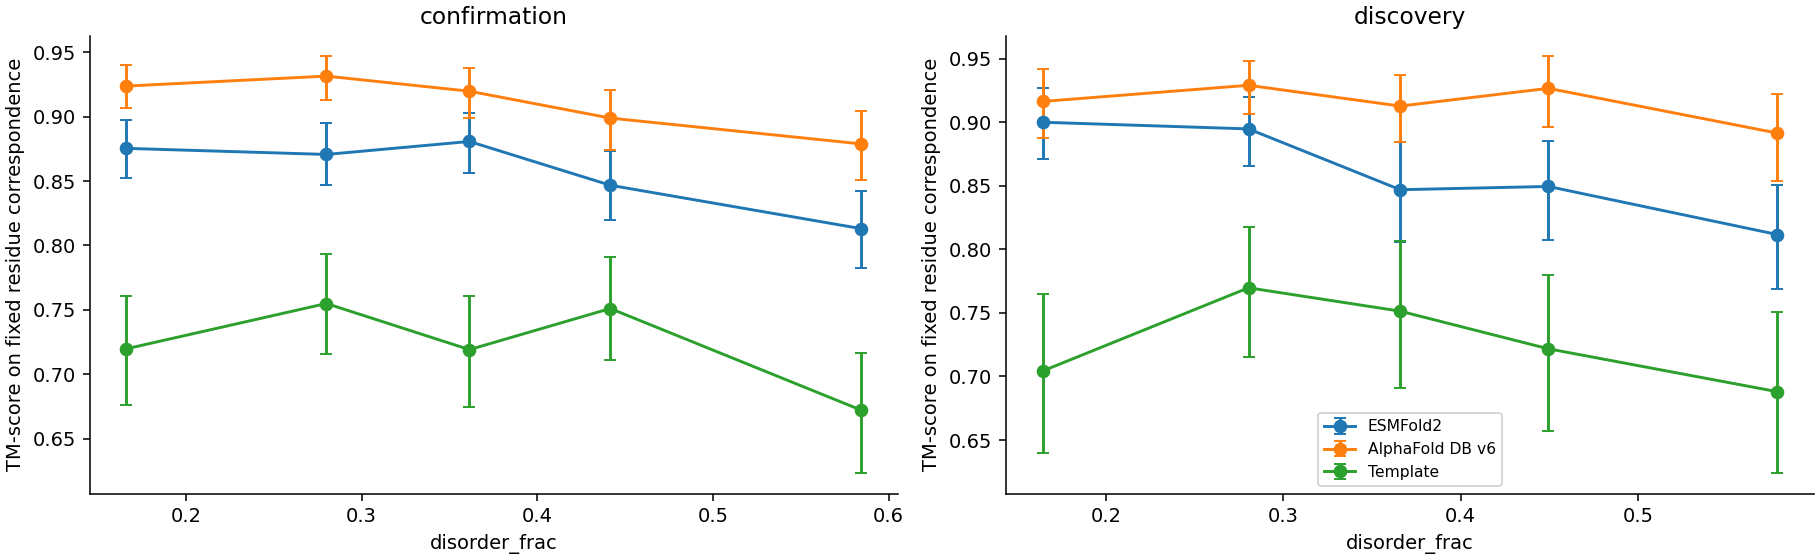

,split,feature,metric,rho,p,adjusted_rho,adjusted_p,n
0,confirmation,homology,tmscore_ca,0.208376,3.447578e-15,0.164146,7.049425e-10,1399
1,confirmation,homology,lddt_ca,0.258768,7.713470e-23,0.225229,1.720371e-17,1399
2,confirmation,homology,gdt_ts,0.184874,3.195607e-12,0.161063,1.469961e-09,1399
3,confirmation,len,tmscore_ca,0.125221,2.627469e-06,0.186516,2.230398e-12,1399
4,confirmation,len,lddt_ca,-0.091754,5.902342e-04,-0.018905,4.806501e-01,1399
5,confirmation,len,gdt_ts,-0.164335,6.280197e-10,-0.096117,3.259556e-04,1399
6,confirmation,disorder_frac,tmscore_ca,-0.086379,1.220641e-03,-0.082089,2.167921e-03,1399
7,confirmation,disorder_frac,lddt_ca,-0.022905,3.919569e-01,-0.049175,6.653119e-02,1399
8,confirmation,disorder_frac,gdt_ts,-0.034506,1.970930e-01,-0.063951,1.697990e-02,1399
9,confirmation,native_coverage,tmscore_ca,0.148943,2.178429e-08,0.097315,2.739618e-04,1399


n  mean_length  mean_resolution  mean_coverage  \
split        disorder_level                                                     
confirmation Q1              280   311.682143         2.089993       0.934406   
             Q2              280   355.175000         2.037227       0.924401   
             Q3              279   345.103943         2.038879       0.921356   
             Q4              281   358.615658         2.047487       0.906270   
             Q5              279   261.118280         1.909515       0.906926   
discovery    Q1              140   335.000000         2.060098       0.934056   
             Q2              140   343.507143         2.093500       0.922787   
             Q3              141   324.446809         2.060170       0.911685   
             Q4              140   325.285714         2.019946       0.928867   
             Q5              139   279.079137         1.945769       0.905625   

                             mean_homology  mean_disorder  afdb_covered  
split        disorder_level                                              
confirmation Q1                   0.513708       0.156911           216  
             Q2                   0.523090       0.279884           235  
             Q3                   0.503823       0.362056           228  
             Q4                   0.567277       0.444533           239  
             Q5                   0.529576       0.619596           219  
discovery    Q1                   0.491468       0.152213           127  
             Q2                   0.517877       0.277324           118  
             Q3                   0.528601       0.364538           116  
             Q4                   0.538898       0.451331           115  
             Q5                   0.547652       0.609609           105

{'gap': 0.062254310035842364,
 'lo': 0.023713629736303095,
 'hi': 0.10173068676395279,
 'low_n': 280,
 'high_n': 279}

{'matched_reference_homology_difference_in_differences': {'gap': 0.037835235668789796,
  'lo': 0.008900570169851373,
  'hi': 0.06886868938428872,
  'low_n': 471,
  'high_n': 150}}

In [11]:
def interval(values,seed=0,n=2000):
    v=np.asarray(values,float);v=v[np.isfinite(v)]
    if not len(v):return np.nan,np.nan,np.nan
    rng=np.random.default_rng(seed);samples=np.array([rng.choice(v,len(v),replace=True).mean() for _ in range(n)])
    return float(v.mean()),float(np.quantile(samples,.025)),float(np.quantile(samples,.975))
def endpoint(frame,level_column,metric,low,high):
    a=frame.loc[frame[level_column].astype(str).eq(str(low)),metric].dropna().to_numpy();b=frame.loc[frame[level_column].astype(str).eq(str(high)),metric].dropna().to_numpy()
    if min(len(a),len(b))<2:return {'gap':np.nan,'lo':np.nan,'hi':np.nan,'low_n':len(a),'high_n':len(b)}
    rng=np.random.default_rng(0);samples=np.array([rng.choice(a,len(a),replace=True).mean()-rng.choice(b,len(b),replace=True).mean() for _ in range(2000)])
    return {'gap':float(a.mean()-b.mean()),'lo':float(np.quantile(samples,.025)),'hi':float(np.quantile(samples,.975)),'low_n':len(a),'high_n':len(b)}
def partial_rho(frame,feature,metric,controls):
    frame=frame[[feature,metric,*controls]].dropna();n=len(frame)
    if n<20:return {'rho':np.nan,'p':np.nan,'n':n}
    x=stats.rankdata(frame[feature]);y=stats.rankdata(frame[metric]);c=np.column_stack([np.ones(n),*[stats.rankdata(frame[name]) for name in controls]])
    x=x-c@np.linalg.lstsq(c,x,rcond=None)[0];y=y-c@np.linalg.lstsq(c,y,rcond=None)[0]
    rho=float(np.corrcoef(x,y)[0,1]);df=n-np.linalg.matrix_rank(c)-1;p=float(2*stats.t.sf(abs(rho)*np.sqrt(df/max(1-rho*rho,1e-15)),df))
    return {'rho':rho,'p':p,'n':n}
FEATURE,LEVEL_COLUMN=AXIS_SETTINGS
curve_rows=[]
for (split,level),group in measurements.groupby(['split',LEVEL_COLUMN],observed=True):
    for model,metric in [('ESMFold2','tmscore_ca'),('AlphaFold DB v6','afdb_tmscore_ca'),('Template','template_tmscore_ca')]:
        mean,lo,hi=interval(group[metric]);curve_rows.append({'split':split,'level':str(level),'model':model,'n':int(group[metric].notna().sum()),'feature_median':float(group[FEATURE].median()),'mean':mean,'lo':lo,'hi':hi})
curves=pd.DataFrame(curve_rows);display(curves)
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
for ax,(split,subset) in zip(axes,curves.groupby('split',sort=False)):
    for model,group in subset.groupby('model',sort=False):
        group=group.sort_values('feature_median');ax.errorbar(group.feature_median,group['mean'],yerr=[group['mean']-group.lo,group.hi-group['mean']],marker='o',capsize=3,label=model)
    ax.set(title=split,xlabel=FEATURE,ylabel='TM-score on fixed residue correspondence');ax.spines[['top','right']].set_visible(False)
axes[-1].legend(fontsize=8);buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))
control_rows=[]
for split,group in measurements.groupby('split'):
    for feature in ['homology','len','disorder_frac','native_coverage','resolution','lowcomplex_frac','comp_entropy','frac_charged','frac_hydrophobic']:
        controls=[x for x in ['homology','len','resolution','native_coverage','is_em','release_year'] if x!=feature]
        for metric in ['tmscore_ca','lddt_ca','gdt_ts']:
            valid=group[[feature,metric]].dropna();raw=stats.spearmanr(valid[feature],valid[metric]);adjusted=partial_rho(group,feature,metric,controls)
            control_rows.append({'split':split,'feature':feature,'metric':metric,'rho':float(raw.statistic),'p':float(raw.pvalue),'adjusted_rho':adjusted['rho'],'adjusted_p':adjusted['p'],'n':adjusted['n']})
controls=pd.DataFrame(control_rows);display(controls)
coverage_table=measurements.groupby(['split',LEVEL_COLUMN],observed=True).agg(n=('entity_id','size'),mean_length=('len','mean'),mean_resolution=('resolution','mean'),mean_coverage=('native_coverage','mean'),mean_homology=('homology','mean'),mean_disorder=('disorder_frac','mean'),afdb_covered=('afdb_tmscore_ca','count'));display(coverage_table)
conf=measurements[measurements.split.eq('confirmation')].copy();extremes=conf.groupby(LEVEL_COLUMN,observed=True)[FEATURE].median().sort_values().index.tolist()
contrast=endpoint(conf,LEVEL_COLUMN,'tmscore_ca',extremes[0],extremes[-1]);display(contrast)
# The model comparison uses the same examples and same resolved residue positions.
paired=conf[conf.afdb_status.eq('ok')].copy();paired['model_minus_afdb']=paired.matched_afdb_tmscore_ca-paired.afdb_tmscore_ca
paired['homology_tail']=np.where(paired.homology.lt(.1),'orphan',np.where(paired.homology.ge(.7),'high','middle'))
did=endpoint(paired,'homology_tail','model_minus_afdb','high','orphan');display({'matched_reference_homology_difference_in_differences':did})


## 6. What the agent decided, and why

Evaluate the confirmation effect and its uncertainty. Acceptance requires the expected direction, an adjusted p-value below 0.05 and an endpoint interval excluding zero. Greater homology dependence than AlphaFold requires a positive matched-reference difference-in-differences interval. Control associations are reported separately and do not create an independent causal claim.


In [12]:
row=controls[(controls.split=='confirmation')&(controls.feature=='disorder_frac')&(controls.metric=='tmscore_ca')].iloc[0]
accepted=bool(row.adjusted_rho<0 and row.adjusted_p<.05 and contrast['lo']>0)
decision=('Accept the predicted disorder degradation axis.' if accepted else 'Reject the predicted disorder degradation axis under the stated confirmation criteria.')+f" Confirmation adjusted rho={row.adjusted_rho:.3f}, p={row.adjusted_p:.4g}; low-minus-high feature TM contrast={contrast['gap']:.3f} [{contrast['lo']:.3f}, {contrast['hi']:.3f}]."

print(decision)
output=ROOT/'test-03';output.mkdir(exist_ok=True)
curves.to_csv(output/'curves.csv',index=False);controls.to_csv(output/'controls.csv',index=False);coverage_table.to_csv(output/'level_controls.csv')
(output/'decision.json').write_text(json.dumps({'decision':decision,'endpoint':contrast,'matched_reference_difference_in_differences':did},indent=2))
(output/'CALCULATION_RECEIPT.json').write_text(json.dumps({'analysis_id':'esmfold2-opus-r1/test-03','completed':True,'host':socket.gethostname(),'targets':len(measurements),'new_inference_executed':bool(inferred_target_count),'new_prediction_count':inferred_target_count,'source_release_end':SOURCE_RELEASE_END,'sequence_selection_seed':SELECTION_SEED,'search_binding':search_binding,'decision':decision},indent=2))


Accept the predicted disorder degradation axis. Confirmation adjusted rho=-0.082, p=0.002168; low-minus-high feature TM contrast=0.062 [0.024, 0.102].


804